# Credit card fraud detection

Course project by Kartik Agrawal and Ananya Baweja (NMIMS).

This notebook tells the story; the pipeline itself lives in `src/`, so the numbers here are the same ones
`python -m src.evaluate` writes to `results/`.

**Protocol.** The first version of this notebook tuned each model's decision threshold on the test set and then
reported F1, precision and recall on that same test set, which made them optimistic. Now:

1. The 284,807 transactions are split **60 / 20 / 20** (train / validation / test), stratified, seed 42.
2. Feature statistics, the scaler and **SMOTE** see the **training** rows only.
3. Each model's threshold is chosen to maximise F1 on the **validation** set.
4. The **test** set is scored once, at the end. **AUPRC** is the headline metric.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import FeatureBuilder, load_raw, split

df = load_raw()   # Kaggle creditcard.csv if present, else OpenML dataset 1597 (downloaded once, cached in data/)
print(f"{len(df):,} transactions, {df.Class.sum()} frauds ({df.Class.mean():.4%})")
df.head()

284,807 transactions, 492 frauds (0.1727%)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Exploratory analysis

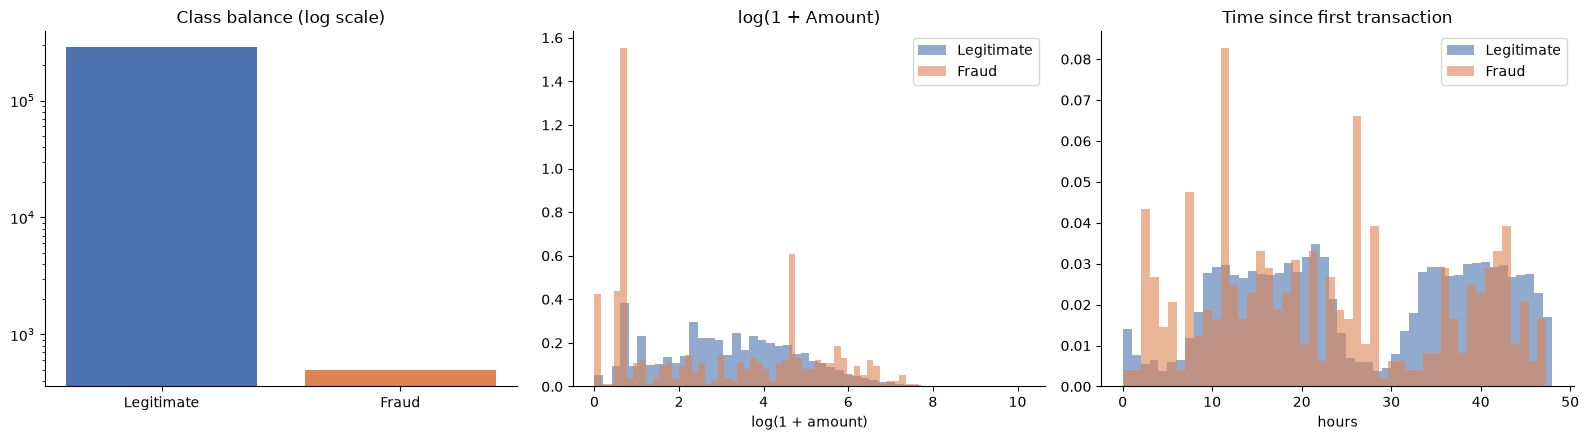

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
counts = df["Class"].value_counts().sort_index()
axes[0].bar(["Legitimate", "Fraud"], counts.values, color=["#4C72B0", "#DD8452"])
axes[0].set_yscale("log"); axes[0].set_title("Class balance (log scale)")
for label, colour, name in [(0, "#4C72B0", "Legitimate"), (1, "#DD8452", "Fraud")]:
    sub = df[df.Class == label]
    axes[1].hist(np.log1p(sub["Amount"]), bins=50, density=True, alpha=0.6, color=colour, label=name)
    axes[2].hist(sub["Time"] / 3600, bins=48, density=True, alpha=0.6, color=colour, label=name)
axes[1].set(title="log(1 + Amount)", xlabel="log(1 + amount)"); axes[1].legend()
axes[2].set(title="Time since first transaction", xlabel="hours"); axes[2].legend()
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [3]:
corr = df.drop(columns=["Time"]).corr()["Class"].drop("Class").sort_values()
print("Most negatively correlated with fraud:"); print(corr.head(5).round(3).to_string())
print("\nMost positively correlated with fraud:"); print(corr.tail(5).round(3).to_string())

Most negatively correlated with fraud:
V17   -0.326
V14   -0.303
V12   -0.261
V10   -0.217
V16   -0.197

Most positively correlated with fraud:
V19    0.035
V21    0.040
V2     0.091
V4     0.133
V11    0.155


## Split and feature engineering

`FeatureBuilder` turns the 30 raw columns into 55 features: amount transforms and quintile bins, hour-of-day
encodings, V-feature ratios, products and absolute values, the aggregate `fraud_signal` and amount × V
interactions. Its quintile edges and time range are learned from the training rows only.

In [4]:
train, val, test = split(df)
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:<10} {len(part):>7,} rows, {part.Class.sum():>3} frauds")

fb = FeatureBuilder().fit(train)
features = fb.transform(train)
print(f"\n{features.shape[1]} features:", ", ".join(features.columns[28:]))

train      170,883 rows, 295 frauds
validation  56,962 rows,  99 frauds
test        56,962 rows,  98 frauds



55 features: Amount_sq, Amount_isZero, Amount_bin, Hour_sin, Hour_cos, Is_night, Is_peak, V1_V2_ratio, V3_V4_ratio, V14_V17_prod, V2_V4_prod, V11_V3_prod, V1_abs, V2_abs, V3_abs, V4_abs, V10_abs, V11_abs, V12_abs, V14_abs, V17_abs, fraud_neg_sum, fraud_pos_sum, fraud_signal, Amount_x_V14, Amount_x_V17, Amount_x_V4


## Train the six models and choose thresholds on validation

The models and hyperparameters are the notebook's originals: XGBoost and Random Forest on SMOTE-balanced
training data, a Keras ANN classifier with class weights, a Keras autoencoder trained on legitimate transactions,
Isolation Forest and Local Outlier Factor. This cell runs the whole pipeline; it takes a while on a CPU.

In [5]:
from src.train import DISPLAY, run

p, results = run()

  xgboost: threshold 0.9825 (validation F1 0.8492), 32s


  random_forest: threshold 0.7198 (validation F1 0.8148), 227s


I0000 00:00:1790703566.685668 3688709 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1790703570.486238 3688709 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1790703570.845071 3688709 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


  ann: threshold 0.9990 (validation F1 0.7912), 100s


  autoencoder: threshold 1.8457 (validation F1 0.3348), 282s


  isolation_forest: threshold 0.6530 (validation F1 0.3963), 26s


  lof: threshold 3.2604 (validation F1 0.0137), 156s


## Evaluate once on the test set

In [6]:
from src.evaluate import test_metrics

rows = []
for name, r in results.items():
    t = test_metrics(p.y_test, r["test_scores"], r["threshold"])
    rows.append({"Model": DISPLAY[name], "AUPRC": t["auprc"], "ROC-AUC": t["roc_auc"], "F1": t["f1"],
                 "Precision": t["precision"], "Recall": t["recall"], "Threshold (val)": r["threshold"],
                 "Frauds caught": f"{t['tp']} / {t['tp'] + t['fn']}", "False alarms": t["fp"]})
table = pd.DataFrame(rows).sort_values("AUPRC", ascending=False).reset_index(drop=True)
table.round(4)

,Model,AUPRC,ROC-AUC,F1,Precision,Recall,Threshold (val),Frauds caught,False alarms
0,XGBoost (SMOTE),0.8678,0.9767,0.8523,0.9615,0.7653,0.9825,75 / 98,3
1,Random Forest (SMOTE),0.8310,0.9730,0.8205,0.8247,0.8163,0.7198,80 / 98,17
2,ANN classifier (class weights),0.7018,0.9791,0.8187,0.8316,0.8061,0.9990,79 / 98,16
3,Autoencoder (reconstruction error),0.4350,0.9653,0.3368,0.2115,0.8265,1.8457,81 / 98,302
4,Isolation Forest,0.4053,0.9624,0.4581,0.4031,0.5306,0.6530,52 / 98,77
5,Local Outlier Factor,0.0033,0.4986,0.0000,0.0000,0.0000,3.2604,0 / 98,53


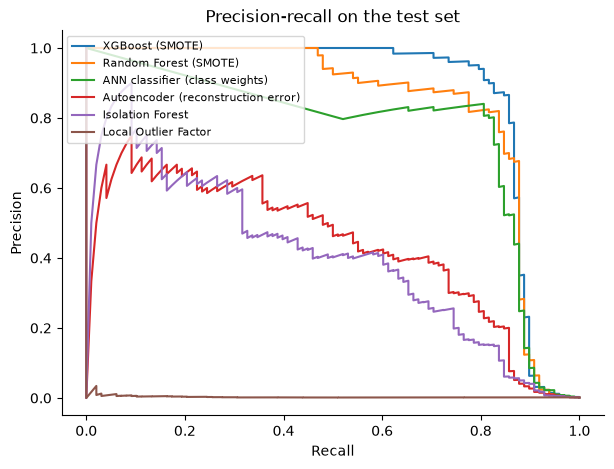

In [7]:
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(7, 5))
for name, r in results.items():
    prec, rec, _ = precision_recall_curve(p.y_test, r["test_scores"])
    ax.plot(rec, prec, label=DISPLAY[name])
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-recall on the test set")
ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False); plt.show()

In [8]:
imp = pd.Series(results["xgboost"]["model"].feature_importances_, index=p.feature_names)
imp.sort_values(ascending=False).head(10).round(4)

fraud_signal    0.2126
Amount_x_V4     0.1346
V14             0.0541
V8              0.0523
V4              0.0476
V2              0.0420
V1              0.0330
V2_abs          0.0314
Amount_x_V14    0.0269
V14_V17_prod    0.0200
dtype: float32

## Takeaways

- Rank models by **AUPRC**: with 0.17% fraud, ROC-AUC is high for almost everything and hides large differences.
- The supervised models beat the anomaly detectors by a wide margin.
- With the threshold chosen on validation, XGBoost's test F1 is lower than the first version's test-tuned figure
  (see the README), which is the optimism the old protocol built in. AUPRC doesn't depend on a threshold.

See the README for the results table and a comparison with the numbers from the first version.